In [ ]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
from collections import Counter
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from textblob import TextBlob
import re


# Path to the CSV file
csv_file_path = 'E:/EGM/editor/editor.csv'

# Read the CSV file with pandas
df = pd.read_csv(csv_file_path)

# Print the DataFrame to inspect its contents
print(df)

                                             File Name  \
0    Electronic Gaming Monthly Issue 007 (February ...   
1    Electronic Gaming Monthly Issue 015 (October 1...   
2    Electronic Gaming Monthly Issue 021 (April 199...   
3    Electronic Gaming Monthly Issue 023 (June 1991...   
4    Electronic Gaming Monthly Issue 028 (November ...   
..                                                 ...   
114  Electronic Gaming Monthly Issue 79 (February 1...   
115  Electronic Gaming Monthly Issue 8 (March 1990)...   
116  Electronic Gaming Monthly Issue 84 (July 1996)...   
117  Electronic Gaming Monthly Issue 9 (April 1990)...   
118  Electronic Gaming Monthly Issue 98 (September ...   

                                               Content  \
0    PLAYING TO WIN...\n\nThere are realmy two diff...   
1    THE HOTTEST VEAR EVER\n\nFOR ELECTRONIC GAMING...   
2    THE POWER OF\n\nRUMORS...\n\nEarlier this mont...   
3    1,000,000 READERS!\n\nSounds impressive We wer...   
4    THE STAT

In [ ]:


df['cleantext'] = df['Content'].str.strip()  # Remove leading and trailing whitespace
df['cleantext'] = df['cleantext'].str.replace(r'\n+', ' ', regex=True)  # Replace multiple newlines with a single space
df['cleantext'] = df['cleantext'].str.replace(r'[^\w\s]', '', regex=True)  # Remove all non-word, non-space characters
df['cleantext'] = df['cleantext'].str.replace(r'\s+', ' ', regex=True)  # Collapse multiple spaces into one
df['cleantext'] = df['cleantext'].str.lower()  # Convert all text to lowercase

In [15]:
df

,File Name,Content,cleantext,tokens,sentiment_score,Year,Month
0,Electronic Gaming Monthly Issue 007 (February ...,PLAYING TO WIN...\n\nThere are realmy two diff...,playing to win there are realmy two different ...,"['playing', 'win', 'realmy', 'two', 'different...",0.062363,1990,02
1,Electronic Gaming Monthly Issue 015 (October 1...,THE HOTTEST VEAR EVER\n\nFOR ELECTRONIC GAMING...,the hottest vear ever for electronic gaming vi...,"['hottest', 'vear', 'ever', 'electronic', 'gam...",0.157092,1990,10
2,Electronic Gaming Monthly Issue 021 (April 199...,THE POWER OF\n\nRUMORS...\n\nEarlier this mont...,the power of rumors earlier this month nintend...,"['power', 'rumors', 'earlier', 'month', 'ninte...",0.119339,1991,04
3,Electronic Gaming Monthly Issue 023 (June 1991...,"1,000,000 READERS!\n\nSounds impressive We wer...",1000000 readers sounds impressive we were plea...,"['readers', 'sounds', 'impressive', 'pleasantl...",0.221348,1991,06
4,Electronic Gaming Monthly Issue 028 (November ...,THE STATE\n\nOF THE INDUSTRY\n\nIt is a welcom...,the state of the industry it is a welcome hono...,"['state', 'industry', 'welcome', 'honor', 'con...",0.172557,1991,11
...,...,...,...,...,...,...,...
114,Electronic Gaming Monthly Issue 79 (February 1...,The suspense is over All of\n\nthe editors hav...,the suspense is over all of the editors have b...,"['suspense', 'editors', 'done', 'expected', 'n...",0.136028,1996,02
115,Electronic Gaming Monthly Issue 8 (March 1990)...,"MORE THAN GOOD LOOKS...\n\nRecently, the staff...",more than good looks recently the staff of egm...,"['good', 'looks', 'recently', 'staff', 'egm', ...",0.091385,1990,03
116,Electronic Gaming Monthly Issue 84 (July 1996)...,By Ed Semrad\n\nor the second year\nF iE a row...,by ed semrad or the second year f ie a row the...,"['ed', 'semrad', 'second', 'year', 'f', 'ie', ...",0.174242,1996,07
117,Electronic Gaming Monthly Issue 9 (April 1990)...,THE FIRST WORD ON VIDEO GAMES...\n\nOne of the...,the first word on video games one of the most ...,"['first', 'word', 'video', 'games', 'one', 'fr...",0.086205,1990,04


In [26]:
df.to_csv('E:/EGM/editor/editor.csv', index=False)

In [ ]:
# Make sure the NLTK tokenizer resource is downloaded
nltk.download('punkt')

def tokenize(text):
    # Tokenize the text with NLTK
    return word_tokenize(text)

# Tokenize the cleaned text column
df['tokens'] = df['cleantext'].apply(tokenize)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\70794\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:

# Calculate the sentiment score, handling non-string input
def calculate_sentiment(text):
    # Check whether the text is a string
    if isinstance(text, str):
        return TextBlob(text).sentiment.polarity
    else:
        # Non-string values (e.g. NaN) get no score
        return None

# Calculate the sentiment score for each row of 'cleantext' and store it in a new column 'sentiment_score'
df['sentiment_score'] = df['cleantext'].apply(calculate_sentiment)

# Print the DataFrame to inspect the new 'sentiment_score' column
print(df)

                                             File Name  \
0    Electronic Gaming Monthly Issue 007 (February ...   
1    Electronic Gaming Monthly Issue 015 (October 1...   
2    Electronic Gaming Monthly Issue 021 (April 199...   
3    Electronic Gaming Monthly Issue 023 (June 1991...   
4    Electronic Gaming Monthly Issue 028 (November ...   
..                                                 ...   
114  Electronic Gaming Monthly Issue 79 (February 1...   
115  Electronic Gaming Monthly Issue 8 (March 1990)...   
116  Electronic Gaming Monthly Issue 84 (July 1996)...   
117  Electronic Gaming Monthly Issue 9 (April 1990)...   
118  Electronic Gaming Monthly Issue 98 (September ...   

                                               Content  \
0    PLAYING TO WIN...\n\nThere are realmy two diff...   
1    THE HOTTEST VEAR EVER\n\nFOR ELECTRONIC GAMING...   
2    THE POWER OF\n\nRUMORS...\n\nEarlier this mont...   
3    1,000,000 READERS!\n\nSounds impressive We wer...   
4    THE STAT

In [ ]:

# Extract the year and month from the file name
def extract_year_month(filename):
    match = re.search(r'\((\w+) (\d{4})\)', filename)
    if match:
        month, year = match.groups()
        month_number = {
            'January': '01', 'February': '02', 'March': '03', 'April': '04',
            'May': '05', 'June': '06', 'July': '07', 'August': '08',
            'September': '09', 'October': '10', 'November': '11', 'December': '12'
        }[month]
        return year, month_number
    return None, None  # No match found: return None for both

# Apply the function and create the new columns
df['Year'], df['Month'] = zip(*df['File Name'].apply(extract_year_month))

print(df[['File Name', 'Year', 'Month']])

                                             File Name  Year Month
0    Electronic Gaming Monthly Issue 007 (February ...  1990    02
1    Electronic Gaming Monthly Issue 015 (October 1...  1990    10
2    Electronic Gaming Monthly Issue 021 (April 199...  1991    04
3    Electronic Gaming Monthly Issue 023 (June 1991...  1991    06
4    Electronic Gaming Monthly Issue 028 (November ...  1991    11
..                                                 ...   ...   ...
114  Electronic Gaming Monthly Issue 79 (February 1...  1996    02
115  Electronic Gaming Monthly Issue 8 (March 1990)...  1990    03
116  Electronic Gaming Monthly Issue 84 (July 1996)...  1996    07
117  Electronic Gaming Monthly Issue 9 (April 1990)...  1990    04
118  Electronic Gaming Monthly Issue 98 (September ...  1997    09

[119 rows x 3 columns]


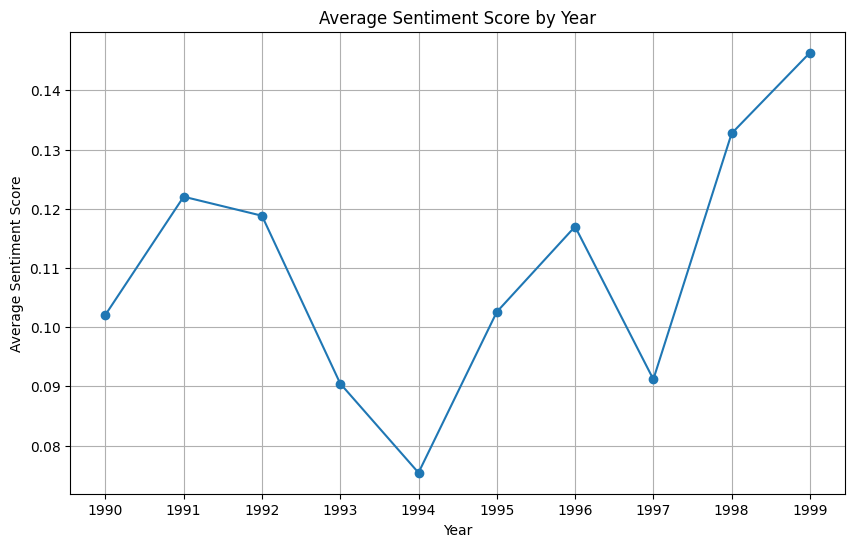

In [ ]:
# Group by year and calculate the mean sentiment score
yearly_sentiment = df.groupby('Year')['sentiment_score'].mean()

# Plot the change in sentiment score over time
plt.figure(figsize=(10, 6))  # Set the figure size
plt.plot(yearly_sentiment.index, yearly_sentiment, marker='o')  # Line chart
plt.title('Average Sentiment Score by Year')  # Chart title
plt.xlabel('Year')  # X-axis label
plt.ylabel('Average Sentiment Score')  # Y-axis label
plt.grid(True)  # Show grid
plt.show()  # Display the chart

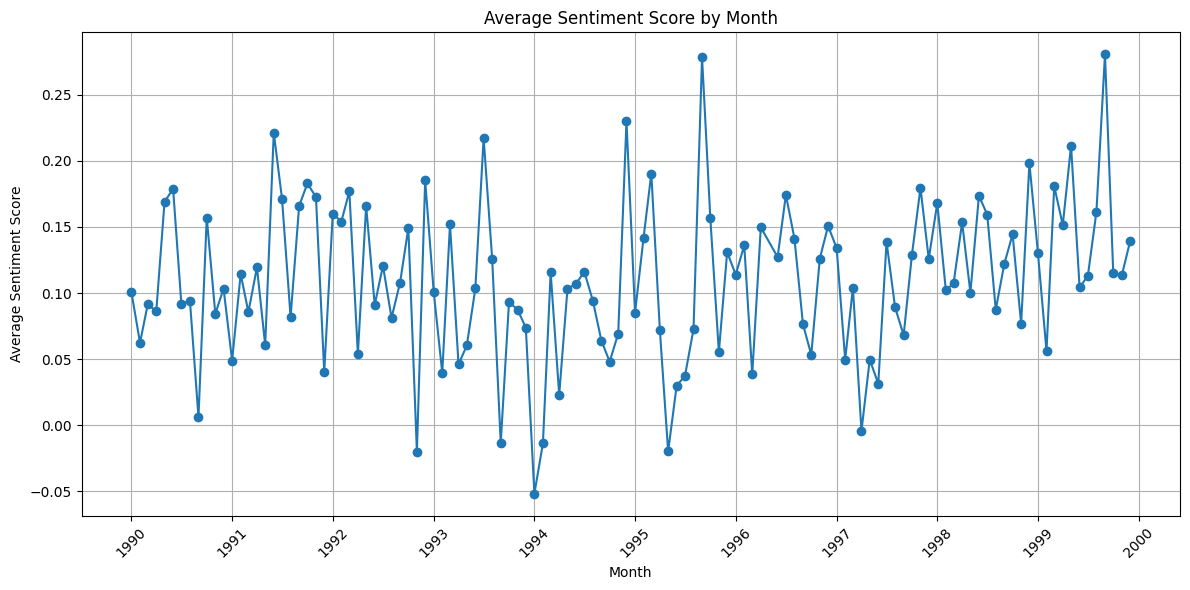

In [ ]:
# Create a date column that identifies each month
df['date'] = pd.to_datetime(df['Year'].astype(str) + '-' + df['Month'].astype(str))

# Group by the date column and calculate the mean sentiment score
monthly_sentiment = df.groupby('date')['sentiment_score'].mean()

# Plot the change in sentiment score over time
plt.figure(figsize=(12, 6))  # Set the figure size
plt.plot(monthly_sentiment.index, monthly_sentiment, marker='o', linestyle='-')  # Line chart with markers
plt.title('Average Sentiment Score by Month')  # Chart title
plt.xlabel('Month')  # X-axis label
plt.ylabel('Average Sentiment Score')  # Y-axis label
plt.xticks(rotation=45)  # Rotate x-axis labels for readability
plt.grid(True)  # Show grid
plt.tight_layout()  # Adjust the layout to fill the figure area
plt.show()  # Display the chart

In [ ]:
# Count word frequencies for each year
yearly_frequency = {}
for year, subset in df.groupby('Year'):
    all_words = [word for sublist in subset['tokens'] for word in sublist]
    word_counts = Counter(all_words)
    yearly_frequency[year] = dict(word_counts)  # Store the frequency of every word

# Print the results
for year in sorted(yearly_frequency):
    print(f"Year {year}:")
    for word, freq in yearly_frequency[year].items():
        print(f"  {word}: {freq}")
    print("\n")

Year 1990:
  playing: 5
  to: 175
  win: 3
  there: 8
  are: 26
  realmy: 1
  two: 4
  different: 5
  kinds: 1
  of: 179
  video: 28
  game: 86
  players: 15
  those: 7
  that: 119
  play: 16
  for: 54
  an: 15
  occasional: 2
  diversion: 1
  and: 164
  it: 31
  is: 49
  the: 368
  later: 2
  group: 2
  this: 48
  spedial: 2
  edition: 3
  electronic: 14
  gaming: 23
  monthmy: 5
  dedicated: 2
  within: 7
  these: 17
  pages: 10
  youll: 11
  find: 7
  all: 30
  secret: 5
  weapons: 1
  hidden: 1
  powerups: 1
  you: 66
  need: 2
  defeat: 1
  enemy: 1
  overcome: 1
  any: 8
  challenge: 1
  meet: 3
  second: 5
  volume: 3
  top: 7
  score: 4
  follows: 1
  in: 93
  footsteps: 1
  its: 17
  predecease: 1
  sort: 1
  with: 63
  dozens: 5
  tips: 6
  tricks: 6
  codes: 3
  strategies: 2
  will: 43
  give: 5
  extra: 2
  winning: 1
  advantage: 1
  help: 2
  push: 1
  over: 6
  learn: 1
  sped: 1
  dial: 1
  controller: 1
  maneuvers: 1
  start: 1
  men: 1
  or: 20
  continues: 2
  tech

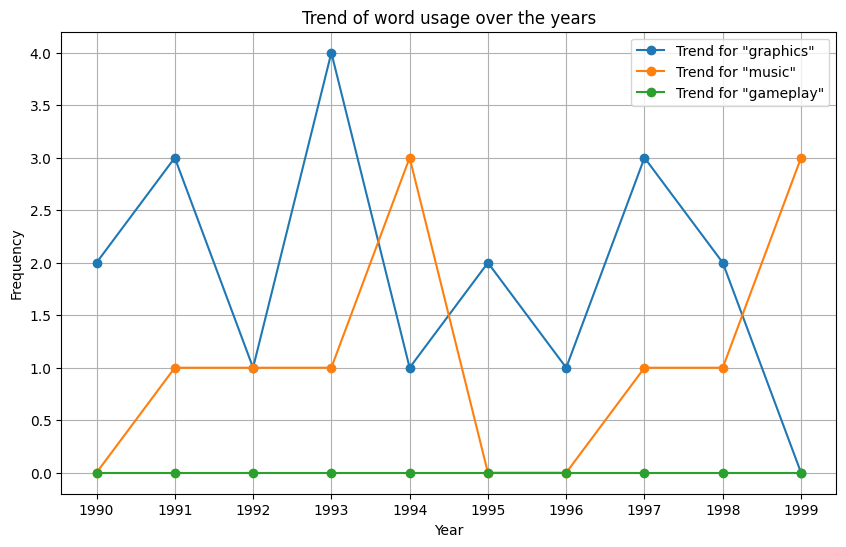

In [ ]:
# Visualize word trends over time
plt.figure(figsize=(10, 6))
for word in ['graphics', 'music', 'gameplay']:  # Example: select words to track
    word_trends = {year: yearly_frequency[year].get(word, 0) for year in sorted(yearly_frequency)}
    plt.plot(list(word_trends.keys()), list(word_trends.values()), marker='o', label=f'Trend for "{word}"')

plt.title('Trend of word usage over the years')
plt.xlabel('Year')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()